In [1]:
import pandas as pd

In [ ]:
import pandas as pd
# Proses Loading Data
laptop = pd.read_csv("laptop_price.csv", encoding="latin1")

laptop.head()

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60


In [ ]:
#membaca info dari data set
laptop.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   laptop_ID         1303 non-null   int64  
 1   Company           1303 non-null   str    
 2   Product           1303 non-null   str    
 3   TypeName          1303 non-null   str    
 4   Inches            1303 non-null   float64
 5   ScreenResolution  1303 non-null   str    
 6   Cpu               1303 non-null   str    
 7   Ram               1303 non-null   str    
 8   Memory            1303 non-null   str    
 9   Gpu               1303 non-null   str    
 10  OpSys             1303 non-null   str    
 11  Weight            1303 non-null   str    
 12  Price_euros       1303 non-null   float64
dtypes: float64(2), int64(1), str(10)
memory usage: 132.5 KB


In [4]:
laptop.describe(include="all")

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
count,1303.000000,1303,1303,1303,1303.000000,1303,1303,1303,1303,1303,1303,1303,1303.000000
unique,NaN,19,618,6,NaN,40,118,9,39,110,9,179,NaN
top,NaN,Dell,XPS 13,Notebook,NaN,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,Windows 10,2.2kg,NaN
freq,NaN,297,30,727,NaN,507,190,619,412,281,1072,121,NaN
mean,660.155794,NaN,NaN,NaN,15.017191,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1123.686992
std,381.172104,NaN,NaN,NaN,1.426304,NaN,NaN,NaN,NaN,NaN,NaN,NaN,699.009043
min,1.000000,NaN,NaN,NaN,10.100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,174.000000
25%,331.500000,NaN,NaN,NaN,14.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,599.000000
50%,659.000000,NaN,NaN,NaN,15.600000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,977.000000
75%,990.500000,NaN,NaN,NaN,15.600000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1487.880000


In [ ]:
# mencari data yang hilang atau kosong
missing_values = laptop.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [6]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [7]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = laptop[less].select_dtypes(include=['number']).columns
laptop[numeric_features] = laptop[numeric_features].fillna(laptop[numeric_features].median())

In [8]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = laptop[less].select_dtypes(include=['object']).columns

for column in kategorical_features:
    laptop[column] = laptop[column].fillna(laptop[column].mode()[0])

C:\Users\Ahmad Raja\AppData\Local\Temp\ipykernel_20464\1453183606.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  kategorical_features = laptop[less].select_dtypes(include=['object']).columns


In [9]:
df = laptop.drop(columns=over)

In [10]:
print(df.dtypes)
print(df.columns.tolist())

laptop_ID             int64
Company                 str
Product                 str
TypeName                str
Inches              float64
ScreenResolution        str
Cpu                     str
Ram                     str
Memory                  str
Gpu                     str
OpSys                   str
Weight                  str
Price_euros         float64
dtype: object
['laptop_ID', 'Company', 'Product', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price_euros']


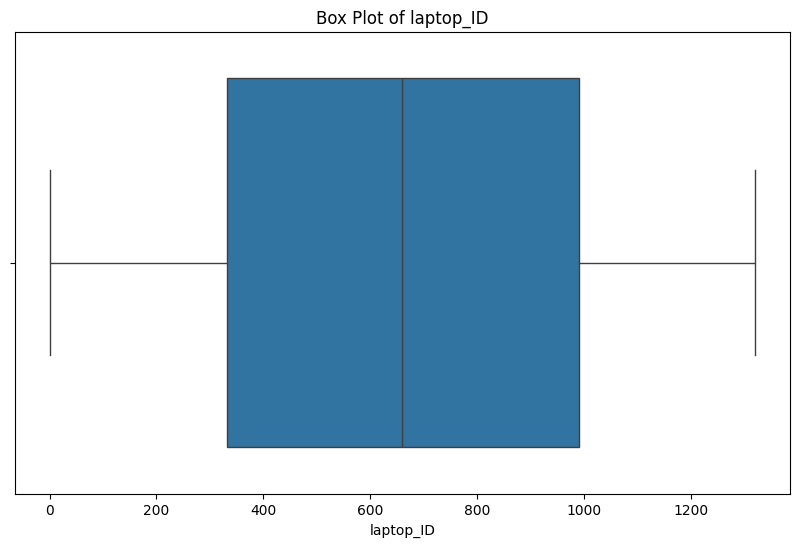

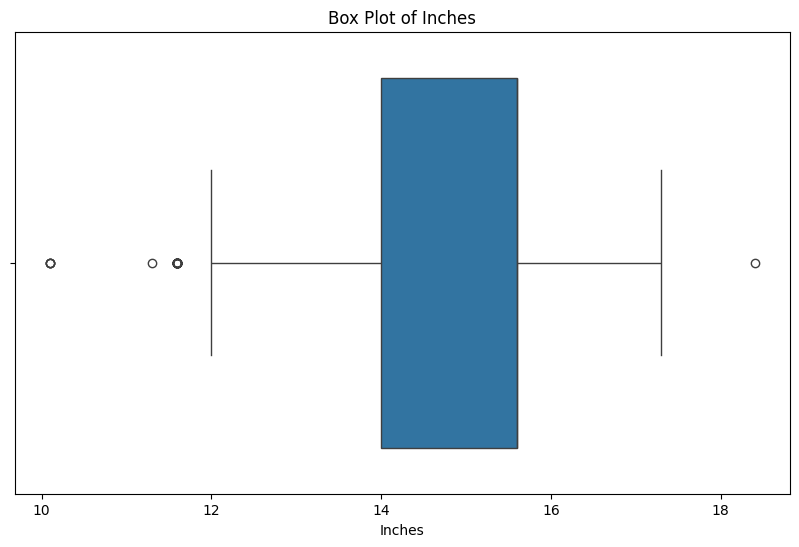

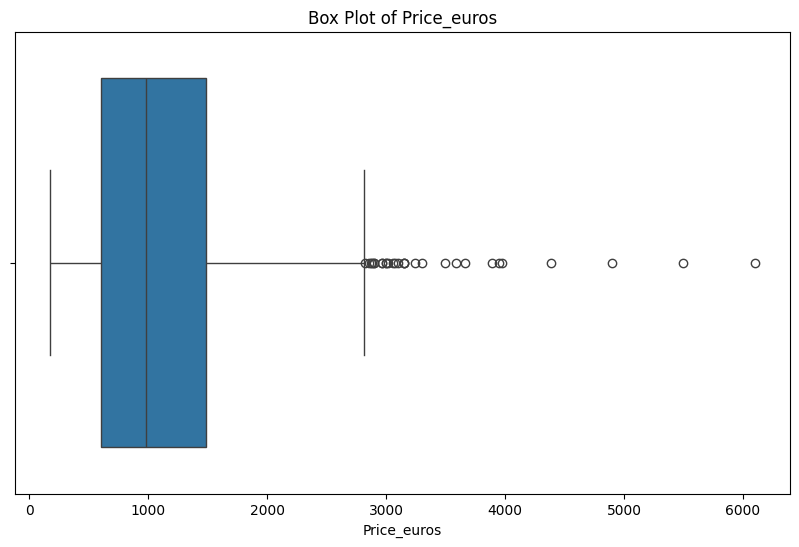

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

#Visualisasi Data numerik menjadi box plot
for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [12]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [13]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

C:\Users\Ahmad Raja\AppData\Local\Temp\ipykernel_20464\1961368722.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=['object']).columns


In [14]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

In [15]:
print(numeric_features)
print(df[numeric_features].dtypes)
print(df.columns.tolist())

Index(['laptop_ID', 'Inches', 'Price_euros'], dtype='str')
laptop_ID      float64
Inches         float64
Price_euros    float64
dtype: object
['laptop_ID', 'Inches', 'Price_euros', 'Company', 'Product', 'TypeName', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight']


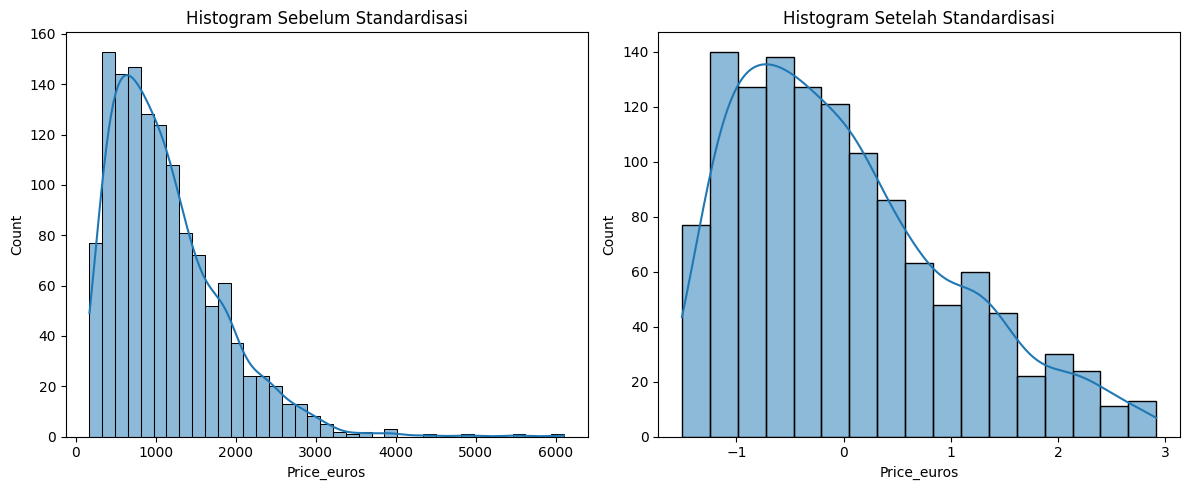

In [16]:

from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# Simpan data sebelum standardisasi
feature = numeric_features[2]
before = laptop[feature].copy()

# Standardisasi data numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

# Visualisasi
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(before, kde=True)
plt.title("Histogram Sebelum Standardisasi")

plt.subplot(1, 2, 2)
sns.histplot(df[feature], kde=True)
plt.title("Histogram Setelah Standardisasi")

plt.tight_layout()
plt.show()


In [17]:
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

C:\Users\Ahmad Raja\AppData\Local\Temp\ipykernel_20464\2319133481.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_features = df.select_dtypes(include=['object']).columns


,Company,Product,TypeName,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight
0,Apple,MacBook Pro,Ultrabook,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg
1,Apple,Macbook Air,Ultrabook,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg
2,HP,250 G6,Notebook,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg
3,Apple,MacBook Pro,Ultrabook,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg
4,Apple,MacBook Pro,Ultrabook,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg
...,...,...,...,...,...,...,...,...,...,...
1298,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg
1299,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg
1300,Lenovo,IdeaPad 100S-14IBR,Notebook,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg
1301,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg


In [18]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,laptop_ID,Inches,Price_euros,Company_Acer,Company_Apple,Company_Asus,Company_Chuwi,Company_Dell,Company_Fujitsu,Company_Google,...,Weight_4.0kg,Weight_4.14kg,Weight_4.2kg,Weight_4.33kg,Weight_4.36kg,Weight_4.3kg,Weight_4.42kg,Weight_4.5kg,Weight_4.6kg,Weight_4kg
0,-1.715132,-1.399245,0.424756,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,-1.712520,-1.399245,-0.320398,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,-1.709908,0.397246,-0.868068,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,-1.707296,0.241029,2.449749,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,-1.704684,-1.399245,1.209065,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,1.719957,-0.852487,-0.761557,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1299,1.722569,-1.399245,0.694093,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1300,1.725182,-0.852487,-1.453033,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1301,1.727794,0.397246,-0.548535,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [19]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil
df_lencoder

,laptop_ID,Inches,Price_euros,Company,Product,TypeName,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight
0,-1.715132,-1.399245,0.424756,1,284,4,23,61,7,4,56,7,37
1,-1.712520,-1.399245,-0.320398,1,285,4,1,59,7,2,49,7,34
2,-1.709908,0.397246,-0.868068,7,50,3,8,70,7,14,51,3,72
3,-1.707296,0.241029,2.449749,1,284,4,25,81,1,27,8,7,69
4,-1.704684,-1.399245,1.209065,1,284,4,23,63,7,14,57,7,37
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,1.719957,-0.852487,-0.761557,10,544,0,13,84,5,4,45,4,76
1299,1.722569,-1.399245,0.694093,10,551,0,19,84,1,27,45,4,40
1300,1.725182,-0.852487,-1.453033,10,184,3,0,33,3,32,38,4,54
1301,1.727794,0.397246,-0.548535,7,2,3,0,84,6,10,19,4,102


In [20]:
# Exploratory Data
df_lencoder.head()

,laptop_ID,Inches,Price_euros,Company,Product,TypeName,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight
0,-1.715132,-1.399245,0.424756,1,284,4,23,61,7,4,56,7,37
1,-1.712520,-1.399245,-0.320398,1,285,4,1,59,7,2,49,7,34
2,-1.709908,0.397246,-0.868068,7,50,3,8,70,7,14,51,3,72
3,-1.707296,0.241029,2.449749,1,284,4,25,81,1,27,8,7,69
4,-1.704684,-1.399245,1.209065,1,284,4,23,63,7,14,57,7,37


In [21]:
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0] # Menampilkan kolom dengan missing values

,Missing Values,Percentage


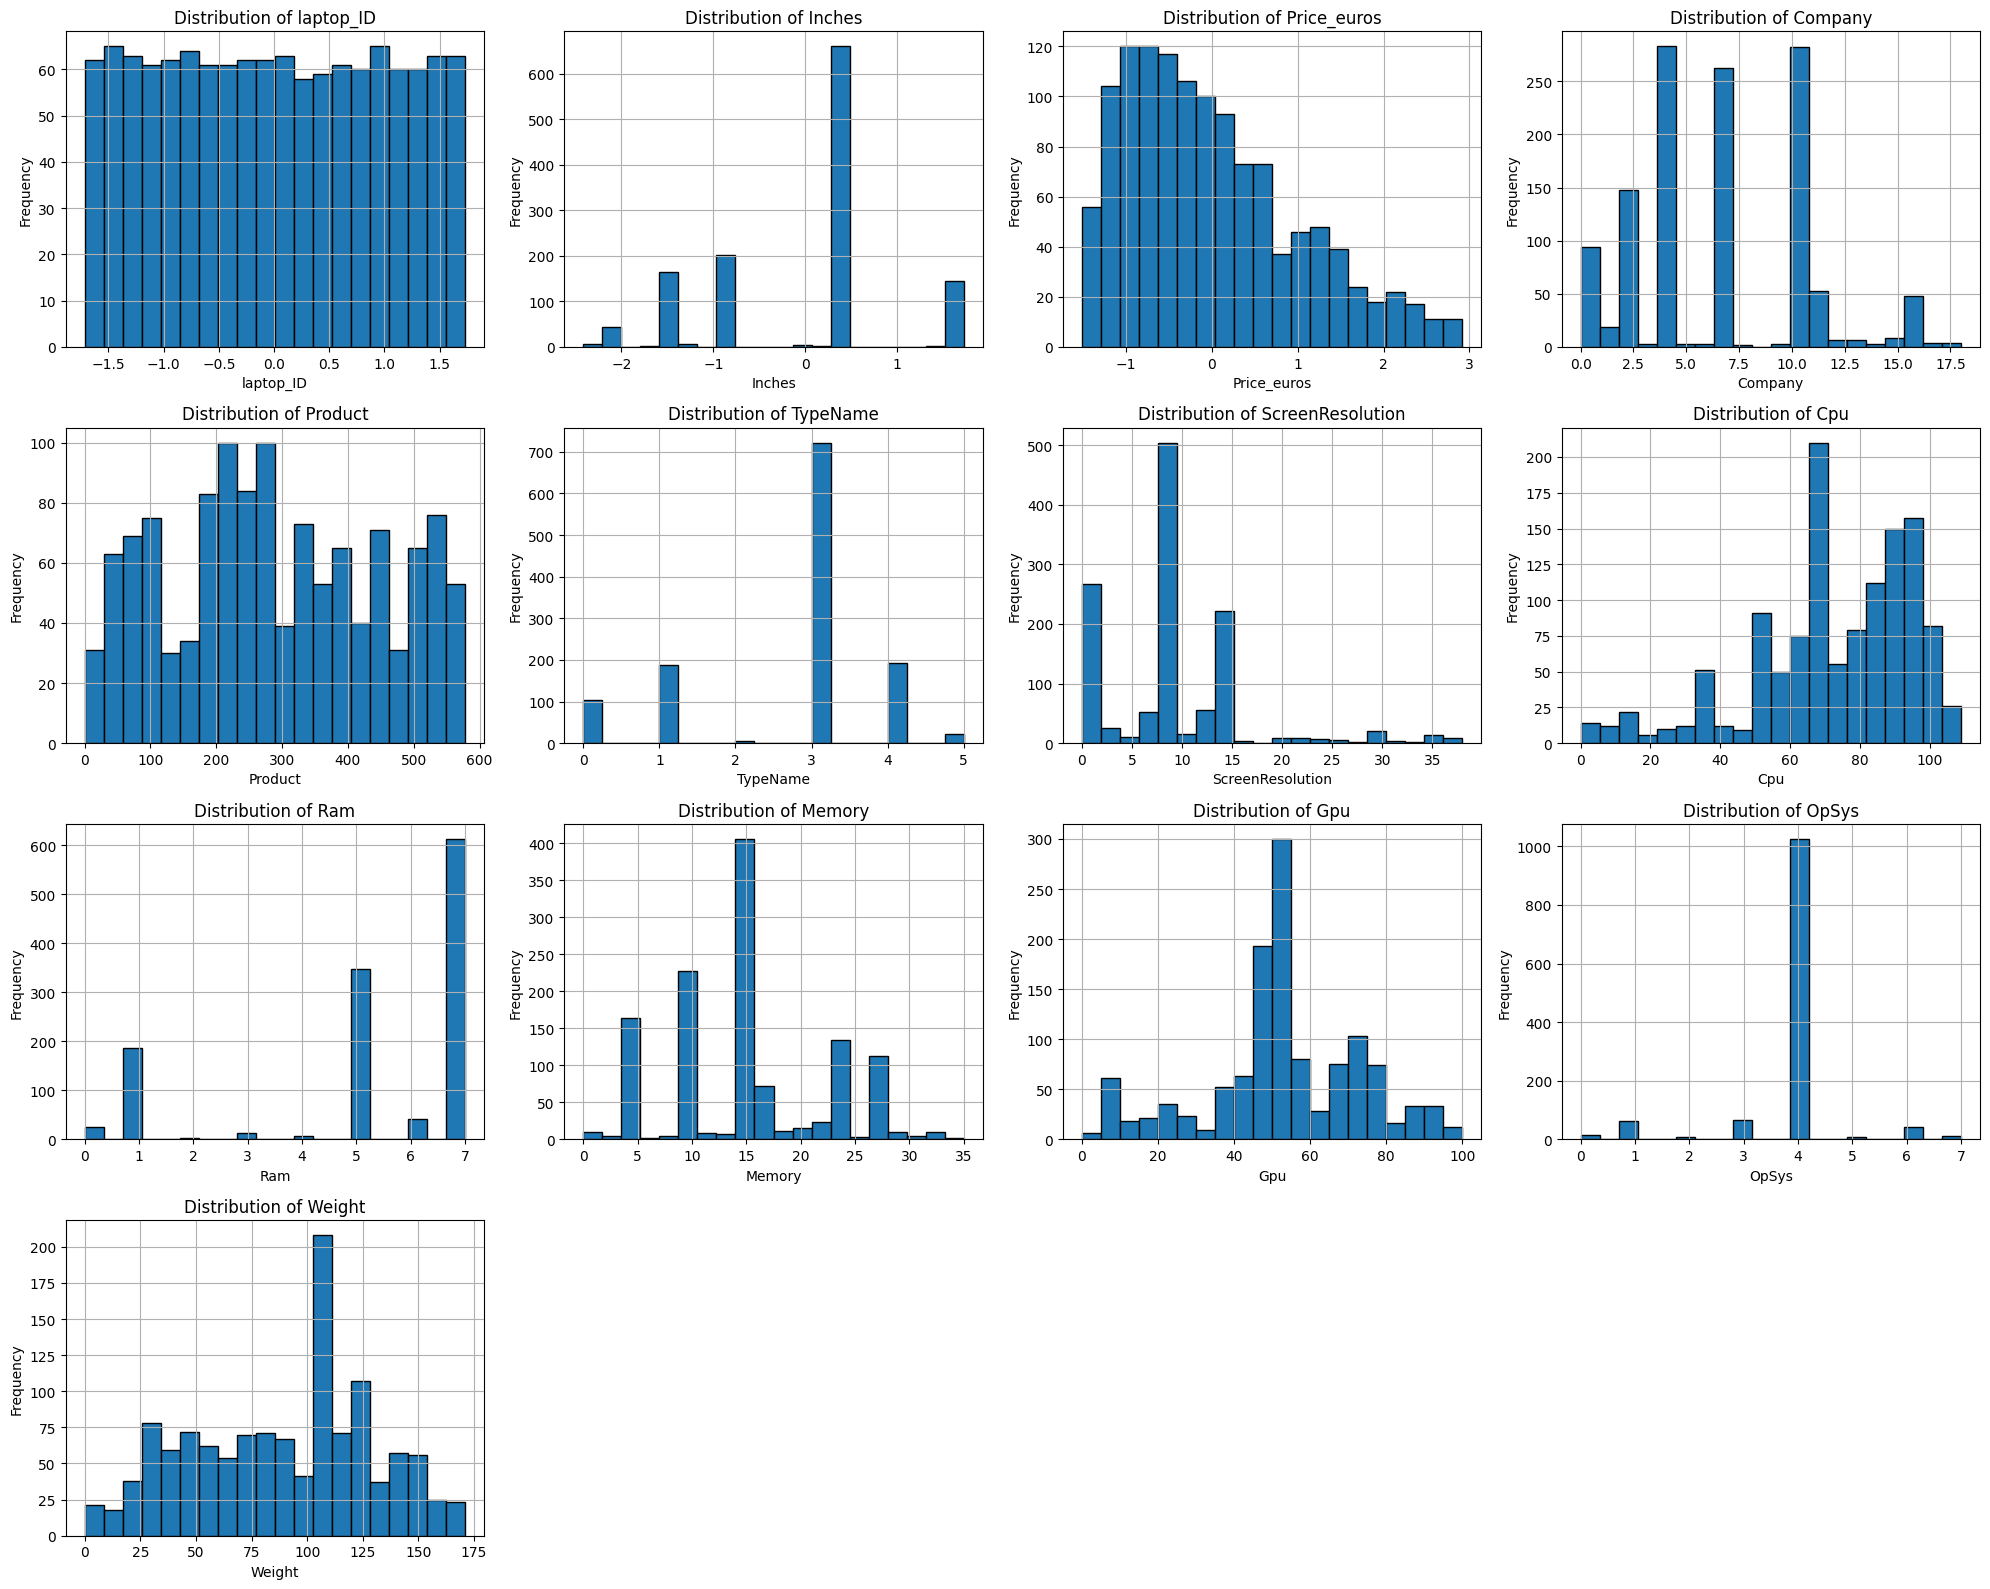

In [22]:

import pandas as pd
import matplotlib.pyplot as plt

# Salin DataFrame agar data asli tetap aman
df_plot = df_lencoder.copy()

# Ubah kolom yang seharusnya numerik menjadi angka
numeric_columns = ['Price_euros', 'Inches', 'Weight']

for column in numeric_columns:
    if column in df_plot.columns:
        df_plot[column] = pd.to_numeric(
            df_plot[column], errors='coerce'
        )

# Pilih semua kolom yang bertipe numerik
numeric_data = df_plot.select_dtypes(include='number')

# Menghitung jumlah variabel numerik
num_vars = numeric_data.shape[1]

# Menentukan grid subplot
n_cols = 4
n_rows = (num_vars + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, n_rows * 4),
    squeeze=False
)

axes = axes.flatten()

# Plot setiap variabel numerik
for i, column in enumerate(numeric_data.columns):
    numeric_data[column].dropna().hist(
        ax=axes[i],
        bins=20,
        edgecolor='black'
    )
    axes[i].set_title(f'Distribution of {column}')
    axes[i].set_xlabel(column)
    axes[i].set_ylabel('Frequency')

# Hapus subplot yang tidak digunakan
for j in range(num_vars, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [23]:
print(df_lencoder.columns.tolist())

['laptop_ID', 'Inches', 'Price_euros', 'Company', 'Product', 'TypeName', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight']


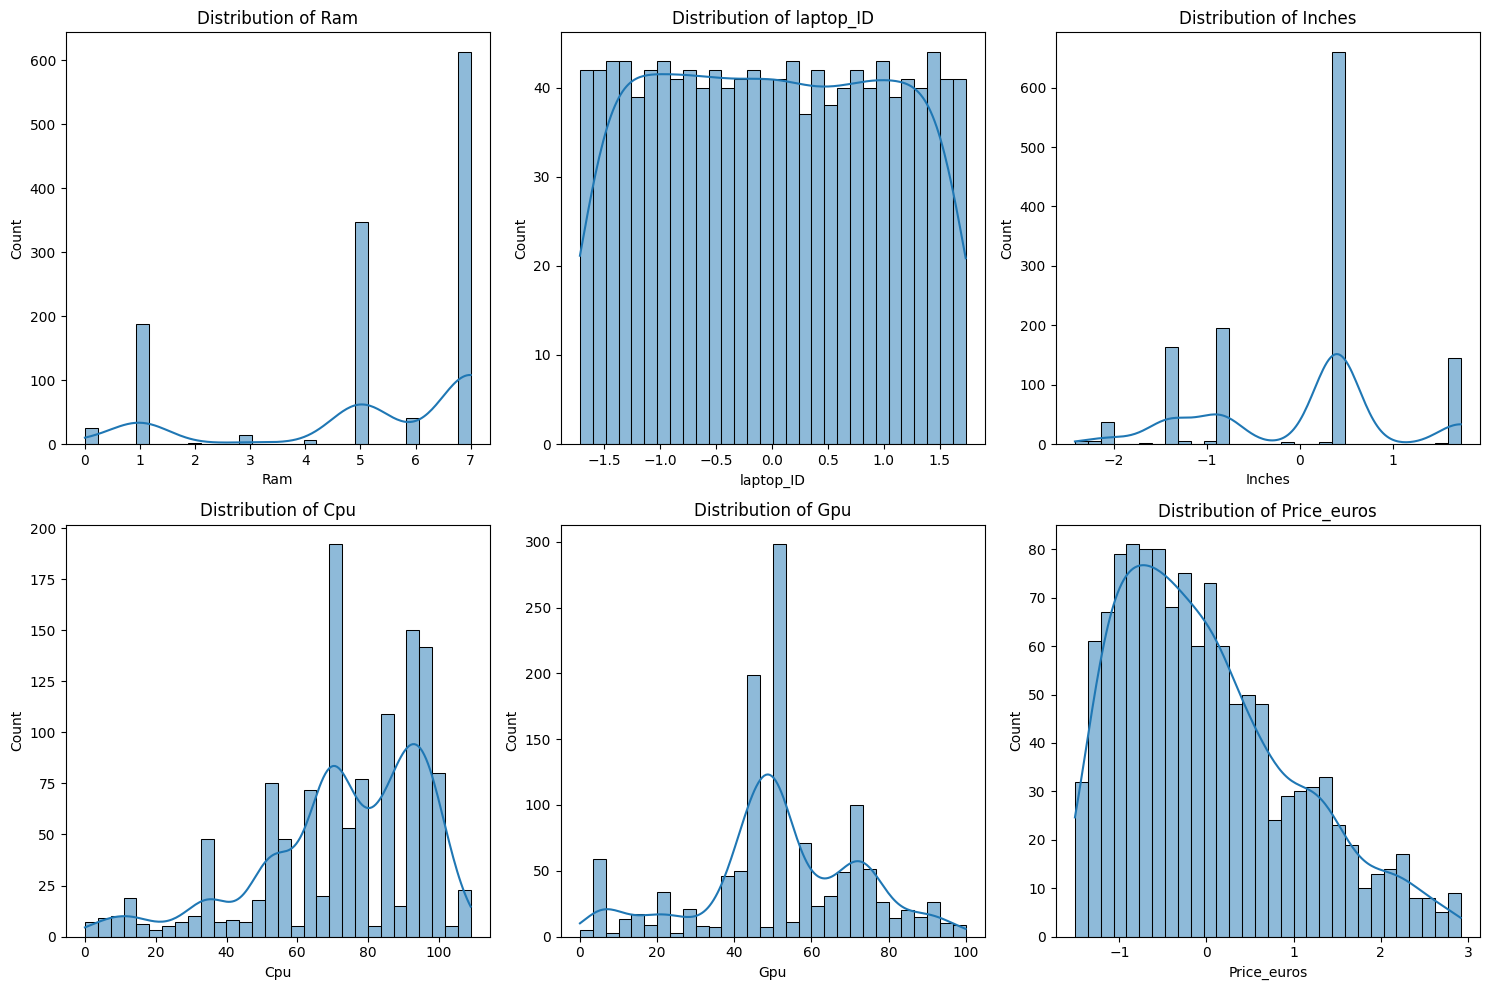

In [24]:

import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi distribusi data untuk beberapa kolom
columns_to_plot = [
    'Ram','laptop_ID',
    'Inches',
    'Cpu','Gpu','Price_euros'
]

plt.figure(figsize=(15, 10))

for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()


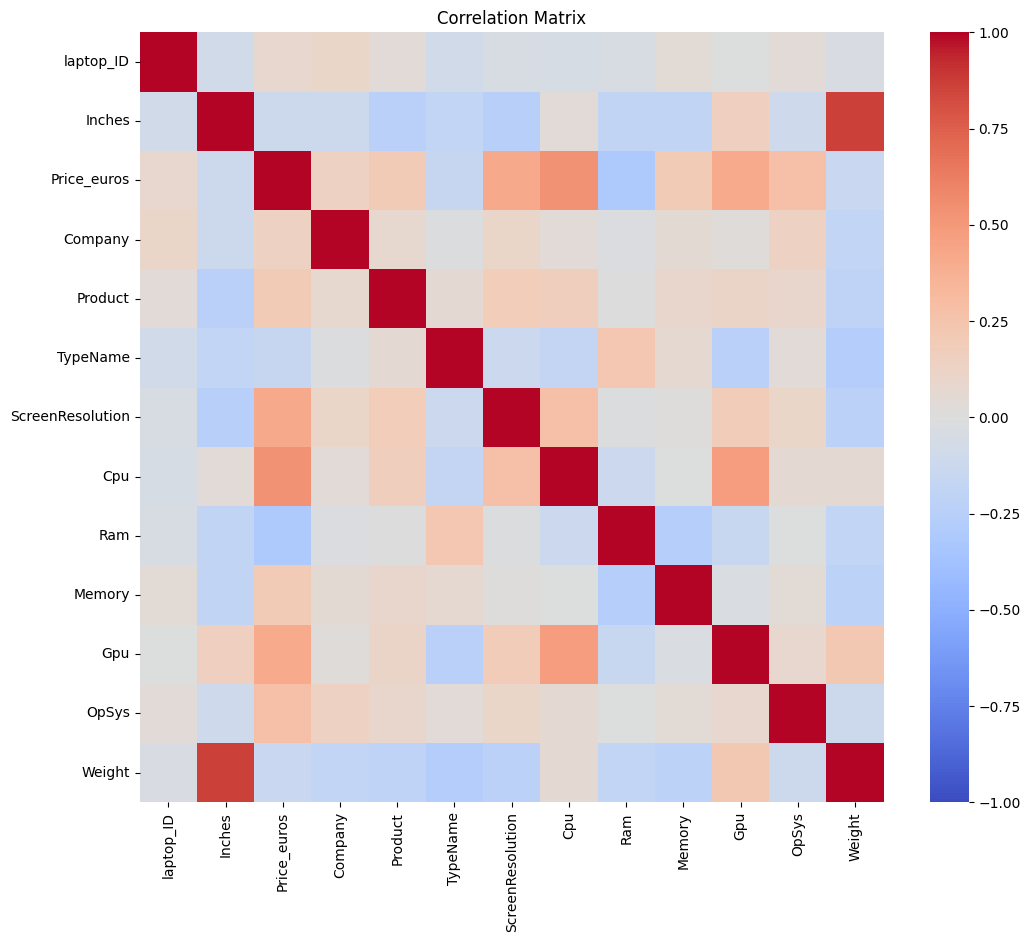

In [25]:
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

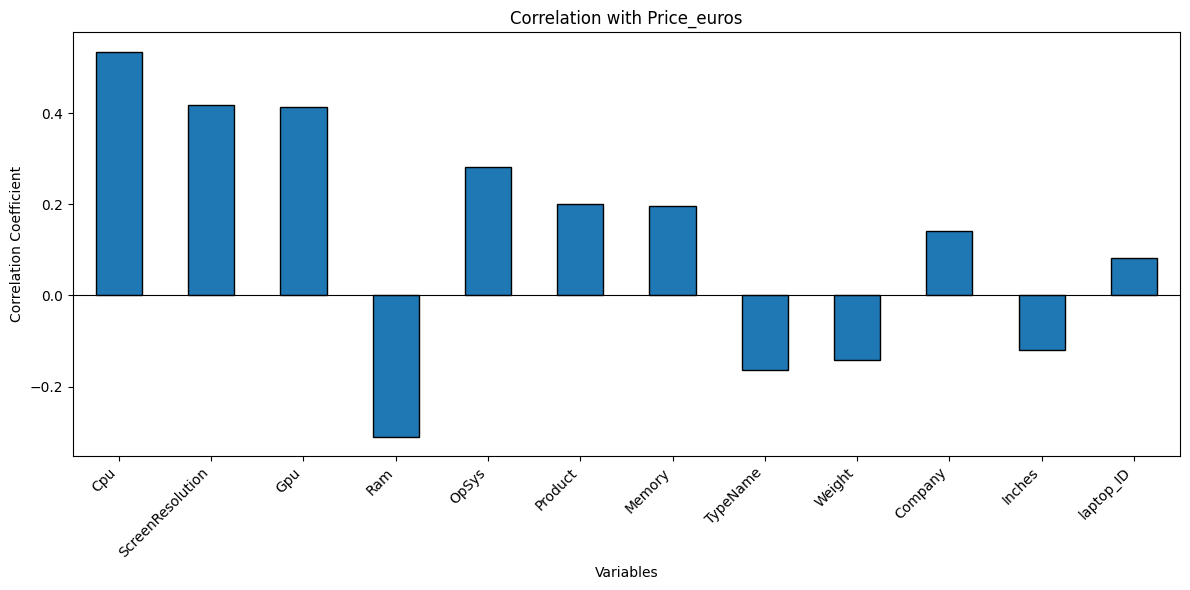

In [26]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pilih kolom numerik saja
numeric_df = df_lencoder.select_dtypes(include='number')

# Hitung korelasi dengan harga laptop
target_corr = numeric_df.corr()['Price_euros']

# Urutkan berdasarkan kekuatan korelasi
target_corr_sorted = target_corr.drop(
    'Price_euros', errors='ignore'
).sort_values(key=abs, ascending=False)

# Buat grafik korelasi
plt.figure(figsize=(12, 6))
target_corr_sorted.plot(kind='bar', edgecolor='black')

plt.title('Correlation with Price_euros')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.axhline(y=0, color='black', linewidth=0.8)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [27]:
X = df_lencoder.drop(columns=['Price_euros']) 
y = df_lencoder['Price_euros'] 

In [28]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing 
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)


In [29]:
# menghitung panjang/jumlah data 
print("Jumlah data: ",len(X))
# menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ",len(x_train))
# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ",len(x_test))

Jumlah data:  1235
Jumlah data latih:  988
Jumlah data test:  247


In [30]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train, y_train)

# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(x_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluasi pada model LARS
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
    }

# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results


,MAE,MSE,R2
Lars,0.775164,0.888684,0.029448


In [32]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results

,MAE,MSE,R2
Lars,0.775164,0.888684,0.029448
Linear Regression,0.549543,0.478548,0.477367


In [33]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,0.775164,0.888684,0.029448
Linear Regression,0.549543,0.478548,0.477367
GradientBoostingRegressor,0.277992,0.154261,0.831528


In [34]:
import joblib
# Menyimpan model ke dalam file
joblib.dump(GBR, 'gbr_model_laptop.joblib')

['gbr_model_laptop.joblib']

In [35]:
import pickle
# Menyimpan model ke dalam file
with open('gbr_model_laptop.pkl', 'wb') as file:
    pickle.dump(GBR, file)


In [36]:
# Memuat model dari file joblib
joblib_model = joblib.load('gbr_model_laptop.joblib')

# Memuat model dari file pickle
with open('gbr_model_laptop.pkl', 'rb') as file:
    pickle_model = pickle.load(file)

In [43]:

from flask import request, jsonify
import joblib

@app.route('/predict', methods=['POST'])
def predict():
    data = request.json['data']  # Mengambil data dari request JSON
    prediction = joblib_model.predict(data)  # Melakukan prediksi
    return jsonify({'prediction': prediction.tolist()})

if __name__ == '__main__':
    app.run(debug=True)


NameError: name 'app' is not defined